In [34]:
import numpy as np
import matplotlib.pyplot as plt
from lmfit import models
from scipy.optimize import leastsq
from scipy.optimize import curve_fit
import os
import pandas as pd


In [ ]:
def importeer(datanaam):
    x_as = []
    y_as = []

    # open file in read mode
    with open(datanaam, 'r', newline='') as file:

        # read and discard first line of file
        next(file)

        for line in file:
            # split column

            line_splitted = line.split(',')
            x = (float(line_splitted[3]))
            y = float(line_splitted[4])
            if x < 0.015:
                x_as.append(x)
                y_as.append(y)

    return x_as, y_as


def lorentz(x, x0, gamma, A):
    return A * ( gamma)**2 / ((x - x0)**2 + (gamma)**2)

def multi_lorentz(x, *params):
    B = params[-1]
    y = np.zeros_like(x, dtype=float) + B
    for i in range(0, len(params) - 1, 3):
        y += lorentz(x, params[i], params[i+1], params[i+2])
    return y


# ── Hoofd-fitfunctie ──────────────────────────────────────────────────────────

def lorentz_fit(x, y, x0_list, A_list,
                gamma_guess=0.001, B_guess=0.0,
                plot=True, title='Lorentz Fit'):
    
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if len(x0_list) != len(A_list):
        raise ValueError("x0_list en A_list moeten even lang zijn.")

    # Startwaarden opbouwen
    p0 = []
    for x0, A in zip(x0_list, A_list):
        p0.extend([x0, gamma_guess, A])
    p0.append(B_guess)

    # Fit
    popt, pcov = curve_fit(multi_lorentz, x, y, p0=p0, maxfev=1000000)
    perr = np.sqrt(np.diag(pcov))
    y_fit = multi_lorentz(x, *popt)

    # Resultaten printen
    N = len(x0_list)
    print(f"{'─'*45}")
    for i in range(N):
        print(f"Piek {i+1}:")
        print(f"  x0    = {popt[i*3]:.5f} ± {perr[i*3]:.5f}")
        print(f"  gamma = {popt[i*3+1]:.5f} ± {perr[i*3+1]:.5f}")
        print(f"  A     = {popt[i*3+2]:.5f} ± {perr[i*3+2]:.5f}")
    print(f"Achtergrond B = {popt[-1]:.5f} ± {perr[-1]:.5f}")
    print(f"{'─'*45}")

    # Plot
    if plot:
        fig, ax = plt.subplots(figsize=(10, 4))
        ax.plot(x, y,     color='green',  label='Data', lw=1.2)
        ax.plot(x, y_fit, color='orange', label='Lorentz fit', lw=1.8, ls='--')

        # Individuele pieken (stippellijnen)
        for i in range(N):
            x0_i, g_i, A_i = popt[i*3], popt[i*3+1], popt[i*3+2]
            B_i = popt[-1]
            y_i = lorentz(x, x0_i, g_i, A_i) + B_i
            ax.plot(x, y_i, lw=0.8, ls=':', label=f'Piek {i+1}')

        ax.set_xlabel('Time (s)')
        ax.set_ylabel('Voltage (V)')
        ax.set_title(title)
        ax.legend()
        plt.tight_layout()
        plt.show()

    return popt, perr

def subtract(x_foreground, y_foreground, x_background, y_background):
    y_interpolated = np.interp(x_foreground, x_background, y_background)
    y_subtracted = y_foreground - y_interpolated

    return x_foreground, y_subtracted


def load_file(number: int, folder_path) -> pd.DataFrame:

    filename = f"TEK{number:04d}.CSV"
    filepath = os.path.join(folder_path, filename)

    if not os.path.exists(filepath):
        print(f"Bestand niet gevonden: {filename}")
        return None

    df = pd.read_csv(
        filepath,
        header=None,
        usecols=[3, 4],
        names=["time", "voltage"],
        encoding="utf-8"
    )

    # Verwijder rijen waar time of voltage geen getal is (de metadata-rijen)
    df = df.apply(pd.to_numeric, errors="coerce").dropna().reset_index(drop=True)

    #print(f"Geladen: {filename} — {len(df)} datapunten")
    x_as = df["time"].values
    y_as = df["voltage"].values
    return x_as, y_as
def file_data(folder_path, N):
    x_subs = []
    y_subs = []

    block_size   = 10   # 10 paren per blok
    block_stride = 20   # sprong tussen blokken (10→30→50→...)
    fg_start     = 10   # eerste foreground index

    fg_block_start = fg_start

    while fg_block_start < N:
        for k in range(block_size):
            fg = fg_block_start + k        # foreground 10..19, 30..39, ...
            bg = fg - 10                   # background 0..9, 20..29, ...

            if fg >= N:
                break

            # Laad foreground & background
            result_fg = load_file(fg, folder_path)
            result_bg = load_file(bg, folder_path)

            if result_fg is None or result_bg is None:
                print(f"Overgeslagen: TEK{fg:04d} of TEK{bg:04d} niet gevonden.")
                continue

            x_foreground, y_foreground = result_fg
            x_background, y_background = result_bg

            # Subtract
            x_subtracted, y_subtracted = subtract(
                x_foreground, y_foreground,
                x_background, y_background
            )

            x_subs.append(x_subtracted)
            y_subs.append(y_subtracted)

            # plotten:
            # plt.plot(x_subtracted, y_subtracted)
            # plt.xlabel("Time (s)")
            # plt.ylabel("Voltage (V)")
            # plt.title(f"Voltage vs Time - TEK{fg:04d} - TEK{bg:04d}, subtracted")
            # plt.show()

        # Volgend blok (10→30→50→...)
        fg_block_start += block_stride

    return x_subs, y_subs

def gemiddelde_grafiek(x_lijst, y_lijst):

    # Gemeenschappelijk x-bereik: van het hoogste minimum tot het laagste maximum
    # (zodat alle grafieken overlappen op dit bereik)
    x_min = max(np.min(x) for x in x_lijst)
    x_max = min(np.max(x) for x in x_lijst)

    # Aantal punten = gemiddelde lengte van de sub-lijsten
    n_punten = int(np.mean([len(x) for x in x_lijst]))

    x_communal = np.linspace(x_min, x_max, n_punten)

    # Interpoleer elke grafiek op het gemeenschappelijke x-grid
    y_geinterpoleerd = np.array([
        np.interp(x_communal, x, y)
        for x, y in zip(x_lijst, y_lijst)
    ])

    # Gemiddelde over alle grafieken
    y_gemiddeld = np.mean(y_geinterpoleerd, axis=0)

    return x_communal, y_gemiddeld

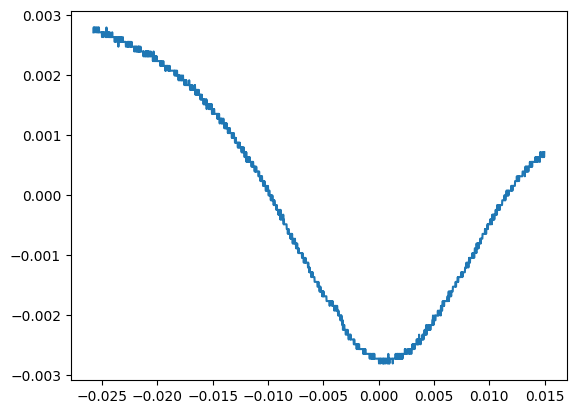

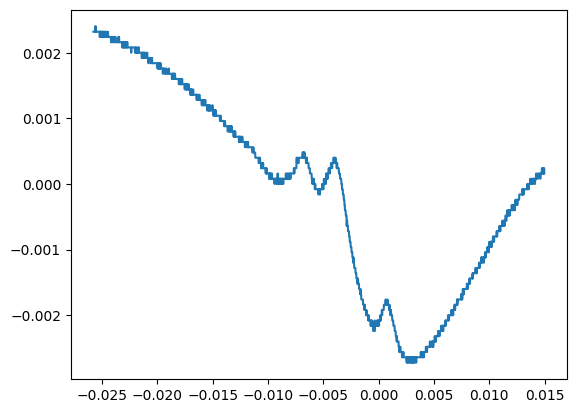

In [36]:
#1 importeren 
x_1,y_1 = importeer('/Users/timwiemer/Desktop/Natuur  en Sterrenkunde/Jaar 1/Rubium_Spectroscopy_group_11/Lambd_dips_8_mesurements_2026_06_15/TEK0000.CSV')
x_2,y_2 = importeer('/Users/timwiemer/Desktop/Natuur  en Sterrenkunde/Jaar 1/Rubium_Spectroscopy_group_11/Lambd_dips_8_mesurements_2026_06_15/TEK0010.CSV')


plt.plot(x_1,y_1)
plt.show()

plt.plot(x_2,y_2)
plt.show()

In [37]:
data_folder = r"/Users/timwiemer/Desktop/Natuur  en Sterrenkunde/Jaar 1/Rubium_Spectroscopy_group_11/Lambd_dips_8_mesurements_2026_06_15"
xjes, ytjes = file_data(data_folder,160)

In [38]:
x_jes_1 = []
y_jes_1 = []

x_jes_2 = []
y_jes_2 = []

x_jes_3 = []
y_jes_3 = []

x_jes_4 = []
y_jes_4 = []

x_jes_5 = []
y_jes_5 = []

x_jes_6 = []
y_jes_6 = []

x_jes_7 = []
y_jes_7 = []

x_jes_8 = []
y_jes_8 = []

for i in range (0,10):
    x_jes_1.append(xjes[i])
    y_jes_1.append(ytjes[i])

for i in range (10,20):
    x_jes_2.append(xjes[i])
    y_jes_2.append(ytjes[i])

for i in range (20,30):
    x_jes_3.append(xjes[i])
    y_jes_3.append(ytjes[i])

for i in range (30,40):
    x_jes_4.append(xjes[i])
    y_jes_4.append(ytjes[i])

for i in range (40,50):
    x_jes_5.append(xjes[i])
    y_jes_5.append(ytjes[i])

for i in range (50,60):
    x_jes_6.append(xjes[i])
    y_jes_6.append(ytjes[i])

for i in range (60,70):
    x_jes_7.append(xjes[i])
    y_jes_7.append(ytjes[i])

for i in range (70,80):
    x_jes_8.append(xjes[i])
    y_jes_8.append(ytjes[i])





[np.float64(-0.0258), np.float64(-0.022468000000000002), np.float64(-0.019136000000000004), np.float64(-0.015804000000000006), np.float64(-0.012472000000000007), np.float64(-0.00914000000000001), np.float64(-0.005808000000000011), np.float64(-0.002476000000000013), np.float64(0.0008559999999999852), np.float64(0.004187999999999983), np.float64(0.0075199999999999816), np.float64(0.01085199999999998), np.float64(0.014183999999999978), np.float64(0.017515999999999976), np.float64(0.020847999999999974)]
-0.0258
0.02418


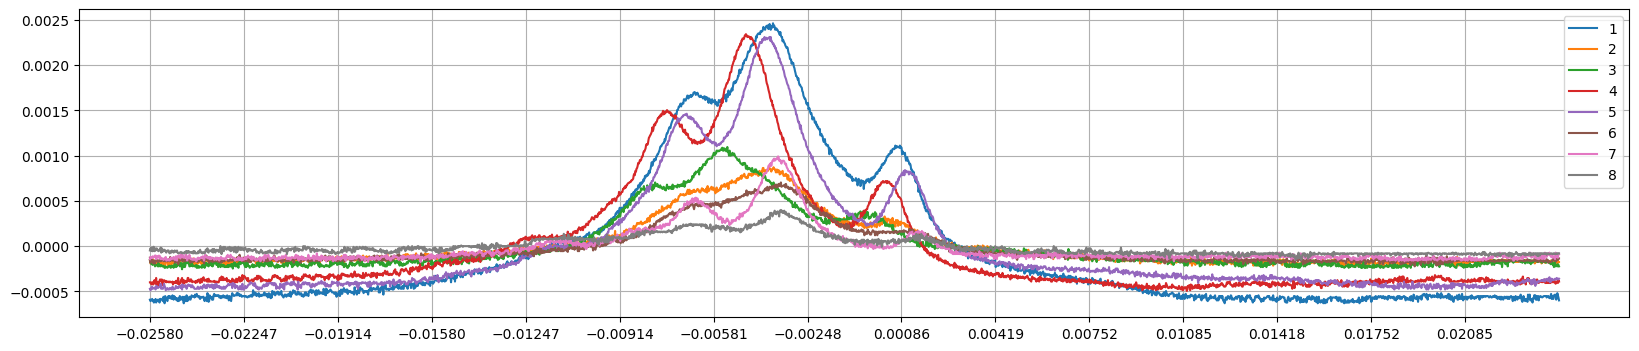

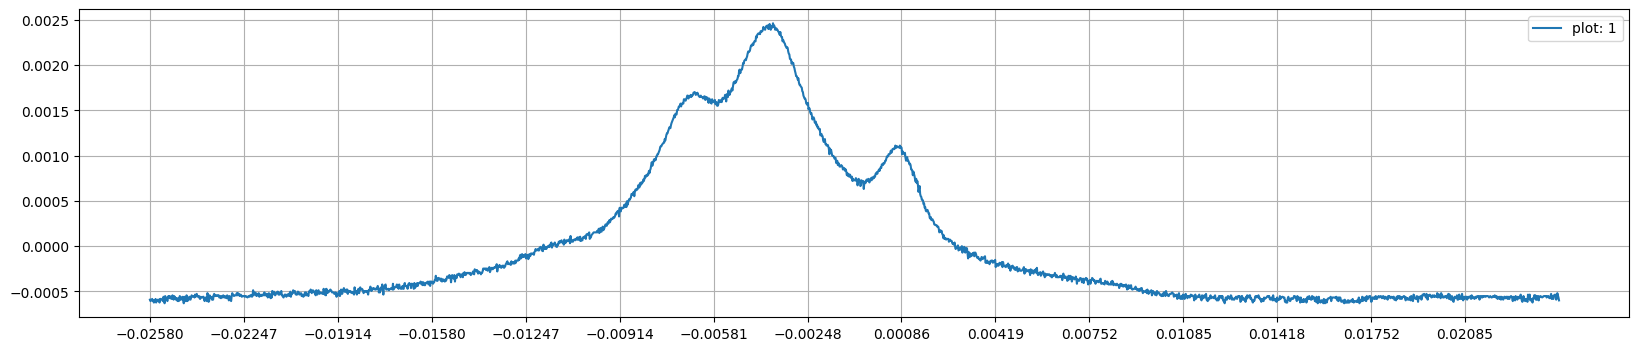

In [96]:
x_avg_1, y_avg_1 = gemiddelde_grafiek(x_jes_1,y_jes_1)
x_avg_2, y_avg_2 = gemiddelde_grafiek(x_jes_2,y_jes_2)
x_avg_3, y_avg_3 = gemiddelde_grafiek(x_jes_3,y_jes_3)
x_avg_4, y_avg_4 = gemiddelde_grafiek(x_jes_4,y_jes_4)
x_avg_5, y_avg_5 = gemiddelde_grafiek(x_jes_5,y_jes_5)
x_avg_6, y_avg_6 = gemiddelde_grafiek(x_jes_6,y_jes_6)
x_avg_7, y_avg_7 = gemiddelde_grafiek(x_jes_7,y_jes_7)
x_avg_8, y_avg_8 = gemiddelde_grafiek(x_jes_8,y_jes_8)
x_tikka = []
x_minna = min(x_avg_1)
x_maxxa = max(x_avg_1)
for i in np.arange(x_minna,x_maxxa,(x_maxxa-x_minna)/15):
    x_tikka.append(i)
print(x_tikka)
print(min(x_avg_1))
print(max(x_avg_1))
plt.figure(figsize=(20,4))
plt.grid()
plt.xticks(x_tikka)
plt.plot(x_avg_1,y_avg_1, label ="1")
plt.plot(x_avg_2,y_avg_2, label ="2")
plt.plot(x_avg_3,y_avg_3, label ="3")
plt.plot(x_avg_4,y_avg_4, label ="4")
plt.plot(x_avg_5,y_avg_5, label ="5")
plt.plot(x_avg_6,y_avg_6, label ="6")
plt.plot(x_avg_7,y_avg_7, label ="7")
plt.plot(x_avg_8,y_avg_8, label ="8")

plt.legend()
plt.show()


plt.figure(figsize=(20,4))
plt.grid()
plt.xticks(x_tikka)
plt.plot(x_avg_1,y_avg_1, label ="plot: 1")
plt.legend()
plt.show()


─────────────────────────────────────────────
Piek 1:
  x0    = -0.01087 ± 0.00007
  gamma = 0.00360 ± 0.00008
  A     = 0.00034 ± 0.00000
Piek 2:
  x0    = -0.00689 ± 0.00001
  gamma = 0.00144 ± 0.00002
  A     = 0.00129 ± 0.00001
Piek 3:
  x0    = -0.00371 ± 0.00000
  gamma = 0.00199 ± 0.00001
  A     = 0.00267 ± 0.00001
Piek 4:
  x0    = 0.00743 ± 0.00008
  gamma = 0.00110 ± 0.00016
  A     = 0.00008 ± 0.00001
Piek 5:
  x0    = 0.00444 ± 0.00008
  gamma = -0.00190 ± 0.00020
  A     = 0.00014 ± 0.00000
Piek 6:
  x0    = 0.00078 ± 0.00001
  gamma = 0.00107 ± 0.00001
  A     = 0.00115 ± 0.00001
Achtergrond B = -0.00062 ± 0.00000
─────────────────────────────────────────────


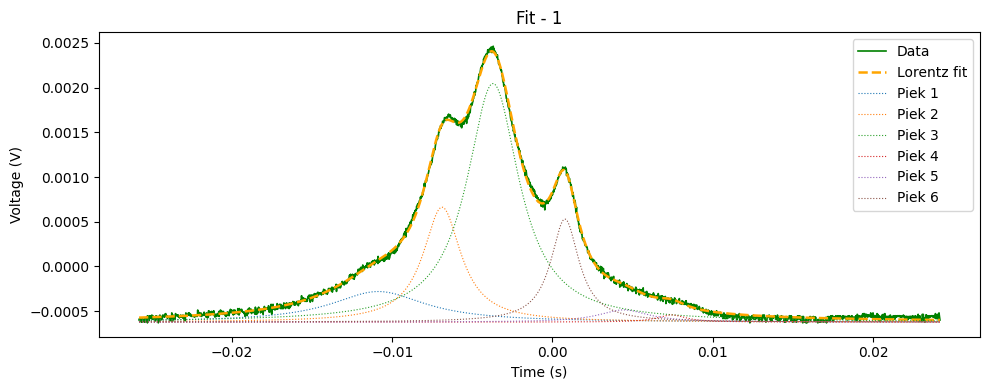

─────────────────────────────────────────────
Piek 1:
  x0    = -0.00624 ± 0.00004
  gamma = 0.00275 ± 0.00003
  A     = 0.00060 ± 0.00001
Piek 2:
  x0    = -0.00356 ± 0.00002
  gamma = 0.00166 ± 0.00003
  A     = 0.00069 ± 0.00001
Piek 3:
  x0    = 0.00065 ± 0.00002
  gamma = 0.00124 ± 0.00004
  A     = 0.00028 ± 0.00000
Piek 4:
  x0    = 0.00408 ± 0.00012
  gamma = -0.00086 ± 0.00024
  A     = 0.00004 ± 0.00000
Piek 5:
  x0    = 0.00576 ± 0.00010
  gamma = -0.00070 ± 0.00016
  A     = 0.00004 ± 0.00001
Achtergrond B = -0.00019 ± 0.00000
─────────────────────────────────────────────


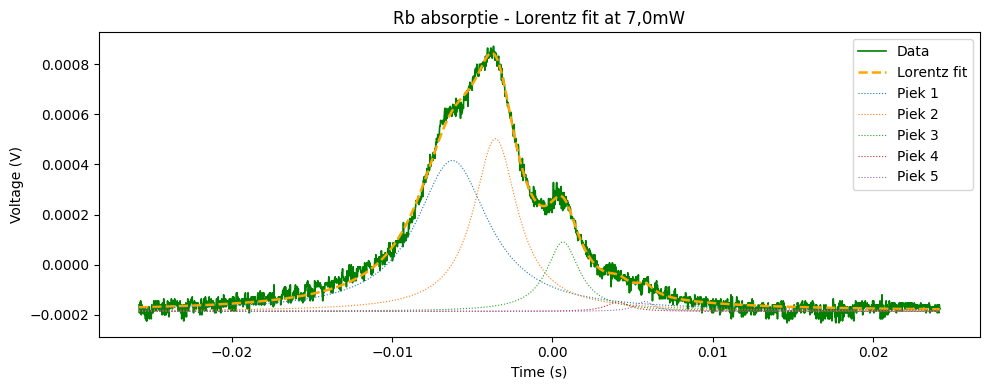

─────────────────────────────────────────────
Piek 1:
  x0    = -0.00874 ± 0.00016
  gamma = 0.00100 ± 0.00007
  A     = 0.00022 ± 0.00006
Piek 2:
  x0    = -0.00807 ± 0.00006
  gamma = 0.00065 ± 0.00009
  A     = 0.00023 ± 0.00007
Piek 3:
  x0    = -0.00529 ± 0.00001
  gamma = 0.00232 ± 0.00002
  A     = 0.00119 ± 0.00000
Piek 4:
  x0    = -0.00030 ± 0.00001
  gamma = 0.00110 ± 0.00003
  A     = 0.00032 ± 0.00000
Piek 5:
  x0    = 0.00474 ± 0.00018
  gamma = -0.00463 ± 0.00028
  A     = 0.00009 ± 0.00000
Achtergrond B = -0.00023 ± 0.00000
─────────────────────────────────────────────


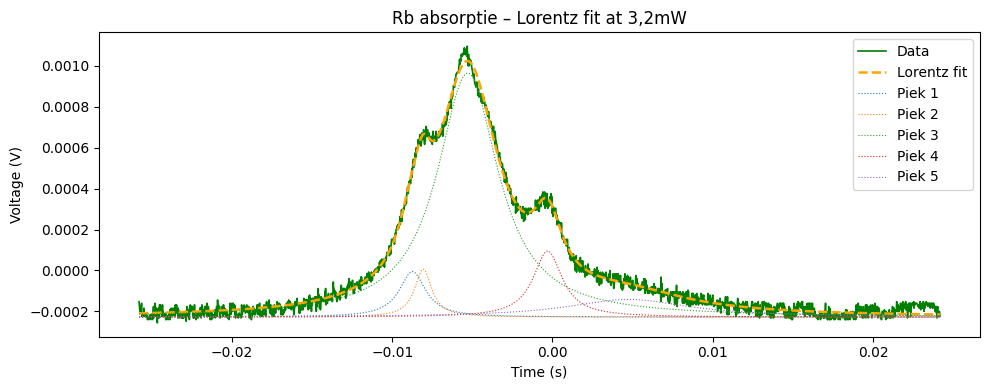

─────────────────────────────────────────────
Piek 1:
  x0    = 0.00663 ± 0.00028
  gamma = 0.00134 ± 0.00050
  A     = -0.00041 ± 0.00008
Piek 2:
  x0    = 0.01226 ± 0.00040
  gamma = 0.00256 ± 0.00090
  A     = -0.00048 ± 0.00007
Piek 3:
  x0    = 0.02037 ± 0.00039
  gamma = -0.00412 ± 0.00093
  A     = -0.00069 ± 0.00005
Achtergrond B = 0.00021 ± 0.00002
─────────────────────────────────────────────


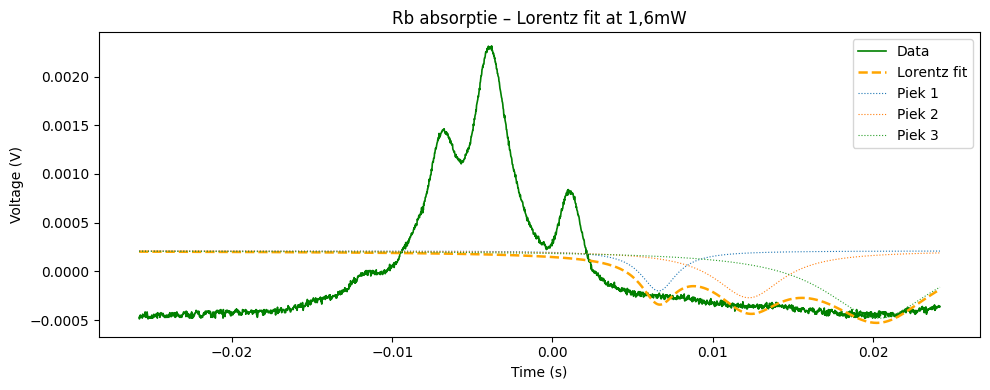

In [99]:
x0_1_list  = [-0.01247, -0.006, -0.003, 0.0086, 0.00752, 0.0005]
A_1_list   = [-0.00003, 0.0015, 0.0025, 0.0012,-0.0005, 0.004]

popt_1, perr_1 = lorentz_fit(
    x_avg_1, y_avg_1,
    x0_list     = x0_1_list,
    A_list      = A_1_list,
    gamma_guess = 0.0001,
    B_guess     = 0.001,
    title       = 'Fit - 1'
)

x0_2_list  = [-0.00589, -0.003, 0.00086, 0.00450, 0.00390]
A_2_list   = [0.0006, 0.0009, 0.0003, 0, 0]

popt_2, perr_2 = lorentz_fit(
    x_avg_2, y_avg_2,
    x0_list     = x0_2_list,
    A_list      = A_2_list,
    gamma_guess = 0.0001,
    B_guess     = 0.001,
    title       = 'Rb absorptie - Lorentz fit at 7,0mW'
)

x0_3_list  = [-0.01247, -0.0080, -0.00581, 0, 0.00419]
A_3_list   = [-0.0001, 0.0006, 0.0010, 0.0004,0]

popt_3, perr_3 = lorentz_fit(
    x_avg_3, y_avg_3,
    x0_list     = x0_3_list,
    A_list      = A_3_list,
    gamma_guess = 0.0001,
    B_guess     = 0.001,
    title       = 'Rb absorptie – Lorentz fit at 3,2mW'
) 




x0_5_list  = [0.007, 0.008, 0.011]
A_5_list   = [0.00083, 0.0012, 0.0002]

popt_5, perr_5 = lorentz_fit(
    x_avg_5, y_avg_5,
    x0_list     = x0_5_list,
    A_list      = A_5_list,
    gamma_guess = 0.0001,
    B_guess     = 0.001,
    title       = 'Rb absorptie – Lorentz fit at 1,6mW'
)

─────────────────────────────────────────────
Piek 1:
  x0    = -0.00468 ± 0.00005
  gamma = 0.00379 ± 0.00004
  A     = 0.00260 ± 0.00004
Piek 2:
  x0    = -0.00222 ± 0.00003
  gamma = -0.00111 ± 0.00008
  A     = -0.00095 ± 0.00004
Achtergrond B = -0.00051 ± 0.00001
─────────────────────────────────────────────


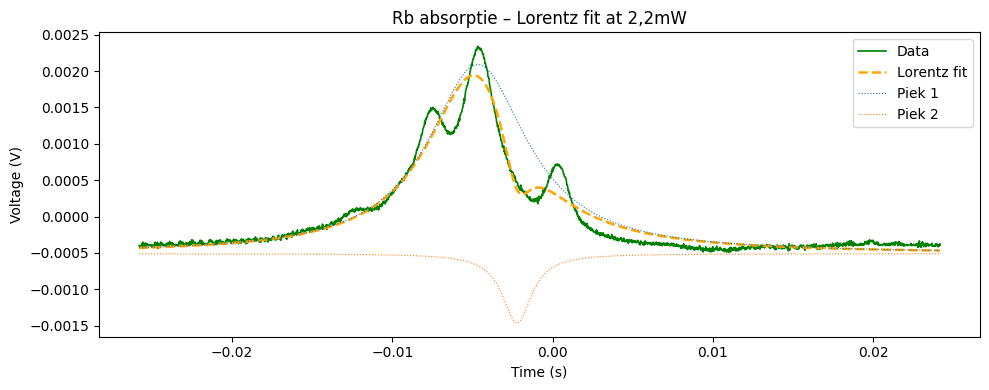

In [95]:
x0_4_list  = [-0.007, -0.003]
A_4_list   = [0.0015, 0.0023]

popt_4, perr_4 = lorentz_fit(
    x_avg_4, y_avg_4,
    x0_list     = x0_4_list,
    A_list      = A_4_list,
    gamma_guess = 0.0001,
    B_guess     = 0.001,
    title       = 'Rb absorptie – Lorentz fit at 2,2mW'
)

In [94]:
ratios = [10.5/0.1, 7.0/2.0, 9.5/2.0, 2.5/0.1, 3.8/0.1, 5.8/2.6, 0.3/0.005, 3.8/0.004]